# گام ۴: مدل پایه
مهدی ظلی پور - آزمایشگاه هوش مصنوعی - بازی دوز

توی این گام یک مدل پایه ساختم که بعداً مینیمکس را با آن مقایسه کنیم. مدل پایه یک بازیکن تصادفی است: هر نوبت یکی از خانه‌های خالی را شانسی انتخاب می‌کند. معیار مقایسه هم درصد برد و مساوی و میانگین تعداد حرکت‌هاست.

## محیط بازی (همان گام ۲)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


class TicTacToeEnv:
    # هشت خط برد (۳ سطر، ۳ ستون، ۲ قطر)
    WIN_LINES = [
        (0, 1, 2), (3, 4, 5), (6, 7, 8),  # سطرها
        (0, 3, 6), (1, 4, 7), (2, 5, 8),  # ستون‌ها
        (0, 4, 8), (2, 4, 6)              # قطرها
    ]

    def __init__(self):
        self.board = np.zeros(9, dtype=int)
        self.current_player = 1  # 1 معادل X، و 1- معادل O
        self.done = False
        self.winner = None

    def reset(self):
        """بازنشانی کامل تخته به وضعیت اولیه"""
        self.board = np.zeros(9, dtype=int)
        self.current_player = 1
        self.done = False
        self.winner = None
        return self.board.copy()

    def get_legal_actions(self):
        """استخراج لیست خانه‌های خالی و مجاز برای بازی (۰ تا ۸)"""
        if self.done:
            return []
        return [i for i, val in enumerate(self.board) if val == 0]

    def check_winner(self):
        """بررسی وضعیت برنده یا تساوی در تخته"""
        for x, y, z in self.WIN_LINES:
            if self.board[x] != 0 and self.board[x] == self.board[y] == self.board[z]:
                return self.board[x]  # برنده: 1 یا 1-
        if 0 not in self.board:
            return 0  # تساوی (Draw)
        return None  # بازی هنوز ادامه دارد

    def step(self, action):
       
        if self.done:
            raise ValueError("بازی به پایان رسیده است؛ ابتدا محیط را reset کنید.")
        
        if action < 0 or action > 8 or self.board[action] != 0:
            raise ValueError(f"حرکت غیرمجاز: خانه {action} پر است یا معتبر نیست.")

        # نشستن مهره بازیکن جاری
        self.board[action] = self.current_player
        
        # بررسی وضعیت بازی
        result = self.check_winner()
        if result is not None:
            self.done = True
            self.winner = result
        else:
            # تغییر نوبت
            self.current_player = -self.current_player

        return self.board.copy(), self.winner, self.done, {}

    def render(self):
        """نمایش تمیز تخته در کنسول"""
        symbols = {1: "X", -1: "O", 0: "."}
        grid = [symbols[val] for val in self.board]
        print("\n وضعیت تخته:")
        for r in range(3):
            print(f" {grid[r*3]} | {grid[r*3+1]} | {grid[r*3+2]} ")
            if r < 2:
                print("---+---+---")
        print()

## بازیکن تصادفی

In [2]:



class RandomBaselineAgent:
    """
    A pure-random baseline agent.
    """

    def __init__(self, player=1, seed=None):
        if player not in (1, -1):
            raise ValueError("player must be 1 (X) or -1 (O).")

        self.player = player
        self.rng = np.random.default_rng(seed)

    def select_action(self, env):
        """
        Select one legal action uniformly at random.
        """

        legal_actions = env.get_legal_actions()

        if not legal_actions:
            return None

        return int(self.rng.choice(legal_actions))

## اجرای ۱۰۰۰ بازی

In [3]:
def first_move_type(a):
    return "Center" if a == 4 else "Corner" if a in (0, 2, 6, 8) else "Edge"

def run_baseline_benchmark(n_games=1000, seed=42):
    env = TicTacToeEnv()
    agent_x = RandomBaselineAgent(player=1, seed=seed)
    agent_o = RandomBaselineAgent(player=-1, seed=seed + 100)
    rows = []
    for game_id in range(n_games):
        env.reset()
        moves, first_x = 0, None
        while not env.done:
            agent = agent_x if env.current_player == 1 else agent_o
            action = agent.select_action(env)
            if action not in env.get_legal_actions():
                raise RuntimeError(f"Illegal action: {action}")
            if env.current_player == 1 and first_x is None:
                first_x = action
            env.step(action)
            moves += 1
        rows.append({"game_id": game_id, "winner": int(env.winner), "moves": moves,
                     "first_move_x": first_x, "pos_type": first_move_type(first_x)})
    return pd.DataFrame(rows)

res = run_baseline_benchmark(n_games=1000, seed=42)
res["result"] = res["winner"].map({1: "X win", -1: "O win", 0: "Draw"})
res.to_csv("baseline_results.csv", index=False)
print(res.shape)

(1000, 6)


## نتیجه

result
X win    59.0
O win    27.7
Draw     13.3
Name: proportion, dtype: float64
average moves: 7.65


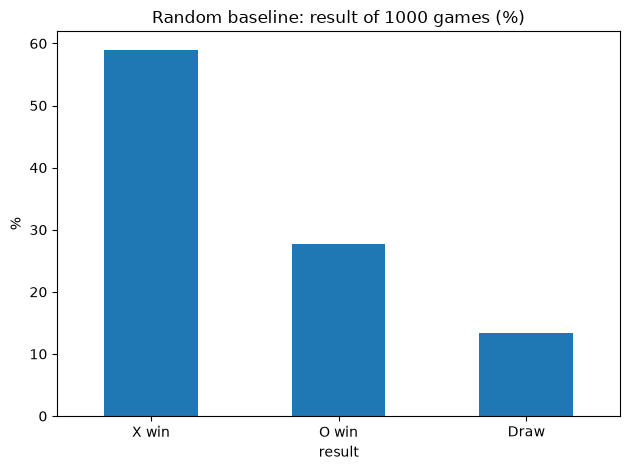

In [4]:
table = res["result"].value_counts(normalize=True).mul(100).round(1).reindex(["X win", "O win", "Draw"])
print(table)
print("average moves:", round(res["moves"].mean(), 2))
table.plot(kind="bar", title="Random baseline: result of 1000 games (%)")
plt.ylabel("%"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("baseline_result.png", dpi=120); plt.show()

## تفسیر
X حدود ۵۹٪ بازی‌ها را برد، O حدود ۲۸٪ و ۱۳٪ هم مساوی شد. دلیلش این است که X اول شروع می‌کند و بازیکن تصادفی اصلاً دفاع نمی‌کند. پس نتیجه می‌گیریم عدد مدل پایه همین‌هاست و مینیمکس باید بهتر از این باشد.

محدودیت: فقط یک بار اجرا کردم (بذر ۴۲) و هنوز با مینیمکس مقایسه نکرده‌ایم.

## متن README
مدل پایه یک بازیکن تصادفی است که هر نوبت یک خانه‌ی خالی را شانسی انتخاب می‌کند. ۱۰۰۰ بازی بین دو بازیکن تصادفی اجرا شد:

| نتیجه | درصد |
|---|---|
| برد X | ۵۹٫۰٪ |
| برد O | ۲۷٫۷٪ |
| مساوی | ۱۳٫۳٪ |
| میانگین حرکت | ۷٫۶۵ |

چیزی که درست کار کرد: با بذر ثابت هر بار همان نتیجه را می‌دهد و حرکت غیرمجاز نداشتیم. محدودیت: فقط یک اجرا بود و فقط تصادفی در برابر تصادفی. در گام بعد با مینیمکس مقایسه می‌کنیم.

فایل‌ها: `step4_baseline.ipynb`، `baseline_results.csv`، `baseline_result.png`